# code_134 · Branch–trunk operators with supervised and equation objectives

**Book:** section 26.2. A self-contained operator-learning laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_26_GUIDE.md), [run evidence](../CHAPTER_26_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_134).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=3134;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 3134


<a id="branch-trunk-contract"></a>
 ## The branch encodes one function; the trunk encodes one query
 Solve −u''=f on[0,1] with zero endpoints. Source128/development32/final64 forcing functions use four sine coefficients;64 additional final functions use frequencies5–8. Thirty-two fixed input sensors sample f. A branch MLP32→32→16 and trunk1→32→16 form an inner product and bias, multiplied by x(1−x) and a source-only output scale. Two recipes each receive learning rates0.003/0.01 and1,200 updates with their own development checkpoint every40updates. Supervised fitting observes33 output values per source function. Equation fitting instead uses finite-difference residuals at31 interior positions of the33-point source query grid and known source forcing there. Development field labels on65 queries select recipe settings; assessment uses129 queries and new whole functions. The physics objective is discretized, not a claim of an exact continuous residual.


,model,parameters,selected_learning_rate,best_update,development_MSE,final_129_query_MSE,higher_frequency_MSE,max_boundary_defect
0,Supervised branch–trunk,2177,0.01,1200,4.545476e-06,0.000014,0.000133,0.0
1,Discrete-physics branch–trunk,2177,0.01,1160,7.253721e-07,0.000008,0.000204,0.0


,recipe,learning_rate,best_update,development_MSE
0,Supervised branch–trunk,0.003,1200,9.790469e-06
1,Supervised branch–trunk,0.010,1200,4.545476e-06
2,Discrete-physics branch–trunk,0.003,1040,2.353861e-06
3,Discrete-physics branch–trunk,0.010,1160,7.253721e-07


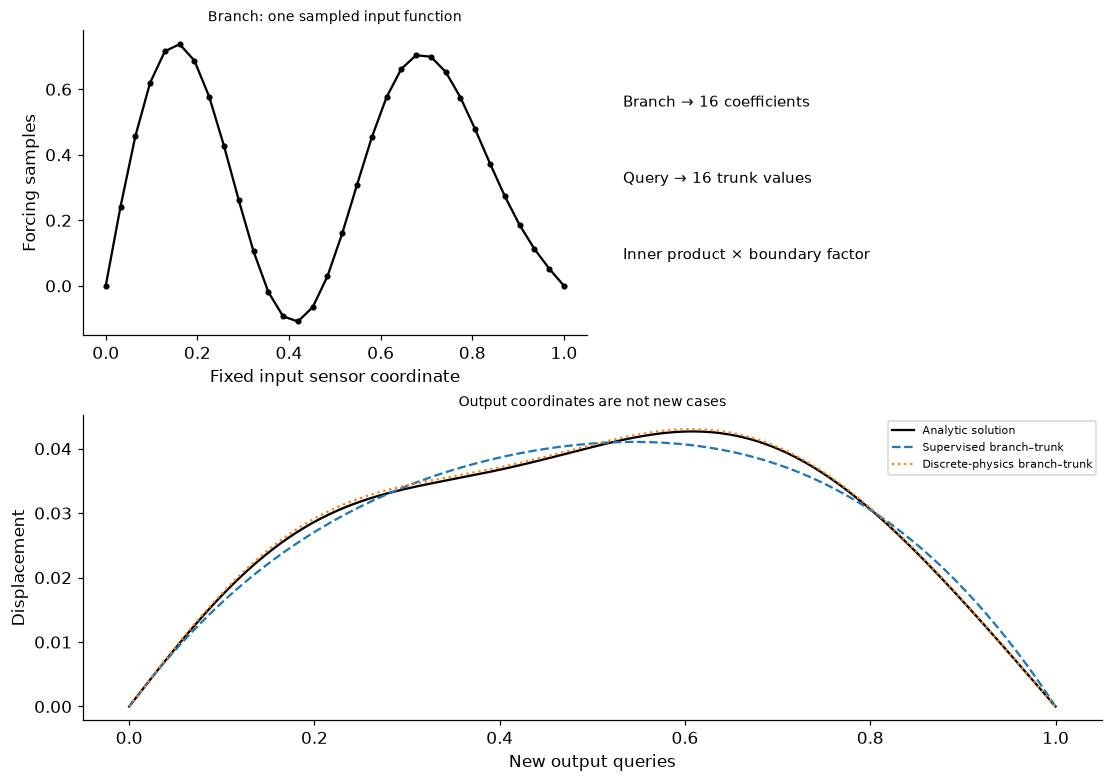

In [2]:
import copy
from sklearn.linear_model import Ridge
low=rng.normal(size=(224,4))/np.arange(1,5);high=rng.normal(size=(64,4))/np.arange(5,9);sensors=np.linspace(0,1,32);train_x=np.linspace(0,1,33);dev_x=np.linspace(0,1,65);final_x=np.linspace(0,1,129)
def values(c,x,modes,solution=False):
    divisor=(np.pi*modes)**2 if solution else np.ones(len(modes));return (c/divisor)@np.sin(np.pi*modes[:,None]*x[None,:])
assert np.max(np.abs(values(np.array([[1.,0,0,0]]),train_x,np.arange(1,5),True)-np.sin(np.pi*train_x)[None,:]/np.pi**2))<1e-15
source_f=values(low[:128],sensors,np.arange(1,5));dev_f=values(low[128:160],sensors,np.arange(1,5));final_f=values(low[160:],sensors,np.arange(1,5));high_f=values(high,sensors,np.arange(5,9));center=source_f.mean(0);spread=source_f.std(0);spread[spread<1e-10]=1;scale=float(np.std(values(low[:128],train_x,np.arange(1,5),True)));fscale=float(np.std(source_f))
X=torch.tensor((source_f-center)/spread);DX=torch.tensor((dev_f-center)/spread);FX=torch.tensor((final_f-center)/spread);HX=torch.tensor((high_f-center)/spread);Y=torch.tensor(values(low[:128],train_x,np.arange(1,5),True));DY=torch.tensor(values(low[128:160],dev_x,np.arange(1,5),True));FY=values(low[160:],final_x,np.arange(1,5),True);HY=values(high,final_x,np.arange(5,9),True);RHS=torch.tensor(values(low[:128],train_x[1:-1],np.arange(1,5)))
class BranchTrunk(nn.Module):
    def __init__(self):super().__init__();self.branch=nn.Sequential(nn.Linear(32,32),nn.Tanh(),nn.Linear(32,16));self.trunk=nn.Sequential(nn.Linear(1,32),nn.Tanh(),nn.Linear(32,16));self.bias=nn.Parameter(torch.zeros(()))
    def forward(self,f,x):return scale*(self.branch(f)@self.trunk(x).T+self.bias)*(x[:,0]*(1-x[:,0]))[None,:]
tx=torch.tensor(train_x)[:,None];dx=torch.tensor(dev_x)[:,None];qx=torch.tensor(final_x)[:,None];models={};rows=[];candidates=[]
for recipe in ['Supervised branch–trunk','Discrete-physics branch–trunk']:
    family_best=np.inf
    for rate in [.003,.01]:
        torch.manual_seed(SEED);model=BranchTrunk();opt=torch.optim.Adam(model.parameters(),lr=rate);best=np.inf
        for step in range(1,1201):
            opt.zero_grad();p=model(X,tx)
            if recipe.startswith('Supervised'):loss=((p-Y)/scale).square().mean()
            else:loss=(-(p[:,2:]-2*p[:,1:-1]+p[:,:-2])/(1/32)**2-RHS).square().mean()/fscale**2
            loss.backward();opt.step()
            if step%40==0:
                with torch.no_grad():score=float((model(DX,dx)-DY).square().mean())
                if score<best:best=score;state=copy.deepcopy(model.state_dict());best_step=step
        candidates.append({'recipe':recipe,'learning_rate':rate,'best_update':best_step,'development_MSE':best})
        if best<family_best:family_best=best;selected=(rate,best_step,state)
    rate,best_step,state=selected;model.load_state_dict(state);models[recipe]=model
    with torch.no_grad():p=model(FX,qx).numpy();hp=model(HX,qx).numpy();b=model(FX,torch.tensor([[0.],[1.]]));branch=model.branch(FX[:1]);trunk=model.trunk(qx[17:18]);trace=scale*(branch@trunk.T+model.bias)*(qx[17,0]*(1-qx[17,0]));torch.testing.assert_close(trace,model(FX[:1],qx[17:18]))
    rows.append({'model':recipe,'parameters':sum(p.numel() for p in model.parameters()),'selected_learning_rate':rate,'best_update':best_step,'development_MSE':family_best,'final_129_query_MSE':float(np.mean((p-FY)**2)),'higher_frequency_MSE':float(np.mean((hp-HY)**2)),'max_boundary_defect':float(b.abs().max())})
    assert float(b.abs().max())==0
# Source-grid regression is a fixed-output comparator; interpolate its output explicitly.
ridge=Ridge(alpha=.001).fit(X.numpy(),Y.numpy());rp=ridge.predict(FX.numpy());rpf=np.stack([np.interp(final_x,train_x,p) for p in rp]);ridge_mse=float(np.mean((rpf-FY)**2))
RESULTS.update(comparisons=rows,candidates=candidates,case_counts=[128,32,64,64],input_sensors=32,source_output_queries=33,development_queries=65,final_queries=129,source_output_scale=scale,analytic_target_check_max_error=float(np.max(np.abs(-((np.pi*np.arange(1,5))**2)*(low[:128]/(np.pi*np.arange(1,5))**2) + low[:128]))),source_supervised_scalar_labels=128*33,physics_source_equation_constraints=128*31,development_field_labels_per_recipe=32*65,interpolated_fixed_grid_Ridge_final_MSE=ridge_mse);display(pd.DataFrame(rows));display(pd.DataFrame(candidates))
fig=plt.figure(figsize=(10,7),layout='constrained');gs=fig.add_gridspec(2,2);axes=[fig.add_subplot(gs[0,0]),fig.add_subplot(gs[0,1]),fig.add_subplot(gs[1,:])];axes[0].plot(sensors,final_f[0],'ko-',markersize=3);axes[0].set(xlabel='Fixed input sensor coordinate',ylabel='Forcing samples',title='Branch: one sampled input function');axes[1].axis('off');axes[1].text(.05,.75,'Branch → 16 coefficients',fontsize=10);axes[1].text(.05,.5,'Query → 16 trunk values',fontsize=10);axes[1].text(.05,.25,'Inner product × boundary factor',fontsize=10);axes[2].plot(final_x,FY[0],'k-',label='Analytic solution')
for name,style in zip(models,['--',':']):
    with torch.no_grad():p=models[name](FX[:1],qx).numpy()[0]
    axes[2].plot(final_x,p,style,label=name)
axes[2].set(xlabel='New output queries',ylabel='Displacement',title='Output coordinates are not new cases');axes[2].legend(fontsize=7);plt.show()


<a id="operator-objective-limits"></a>
 ## The training evidence differs even when the serving computation agrees
 Both branch–trunk recipes accept exactly the same32-sensor contract and query coordinates. The supervised model consumes generated solution fields; the physics recipe consumes the governing equation and its known source forcing, plus development solution labels for selection. It is not free of numerical or validation costs. Discrete residual training can inherit the source grid's truncation error. Finer output queries evaluate the learned trunk without refitting, but do not increase branch input resolution or reveal frequencies absent from source functions. Whole cases remain separated; all query errors within one function are dependent. The original implementation demonstrates the computation pattern rather than a complete DeepXDE package API or published benchmark reproduction.


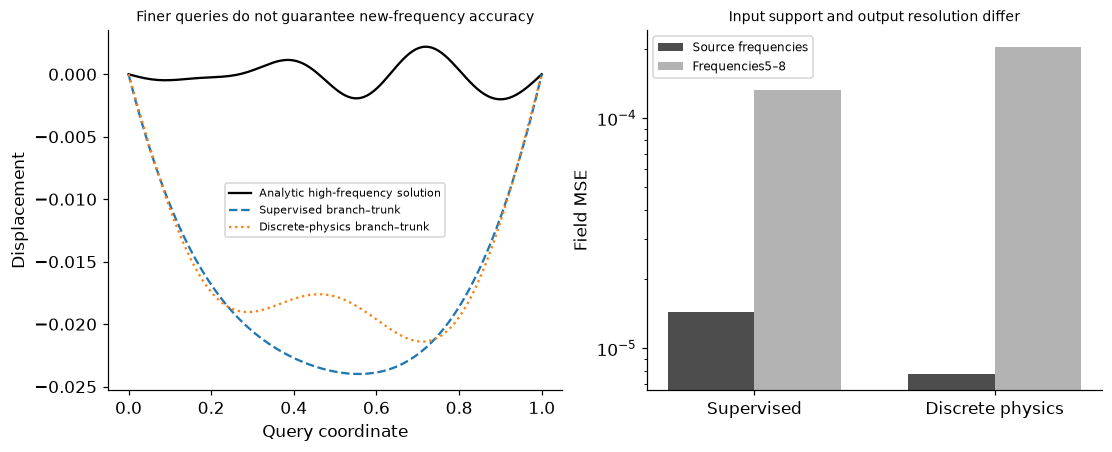

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].plot(final_x,HY[0],'k-',label='Analytic high-frequency solution')
for name,style in zip(models,['--',':']):
    with torch.no_grad():p=models[name](HX[:1],qx).numpy()[0]
    axes[0].plot(final_x,p,style,label=name)
axes[0].set(xlabel='Query coordinate',ylabel='Displacement',title='Finer queries do not guarantee new-frequency accuracy');axes[0].legend(fontsize=7);xx=np.arange(len(rows));axes[1].bar(xx-.18,[r['final_129_query_MSE'] for r in rows],.36,color='.3',label='Source frequencies');axes[1].bar(xx+.18,[r['higher_frequency_MSE'] for r in rows],.36,color='.7',label='Frequencies5–8');axes[1].set(yscale='log',xticks=xx,xticklabels=['Supervised','Discrete physics'],ylabel='Field MSE',title='Input support and output resolution differ');axes[1].legend(fontsize=8);plt.show()
assert len(rows)==2 and all(np.isfinite(r['higher_frequency_MSE']) for r in rows)


In [4]:
summary={'example_id':'code_134','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual native branch-trunk inner-product network', 'fixed input sensors and variable output queries', 'supervised versus discrete physics operator objectives', 'whole-function development selection', 'higher-frequency input-support assessment'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual native branch-trunk inner-product network", "fixed input sensors and variable output queries", "supervised versus discrete physics operator objectives", "whole-function development selection", "higher-frequency input-support assessment"], "elapsed_seconds": 2.191, "example_id": "code_134", "hardware": "Darwin arm64 CPU", "results": {"analytic_target_check_max_error": 2.220446049250313e-16, "candidates": [{"best_update": 1200, "development_MSE": 9.790469115958765e-06, "learning_rate": 0.003, "recipe": "Supervised branch\u2013trunk"}, {"best_update": 1200, "development_MSE": 4.545476368869042e-06, "learning_rate": 0.01, "recipe": "Supervised branch\u2013trunk"}, {"best_update": 1040, "development_MSE": 2.353861439427188e-06, "learning_rate": 0.003, "recipe": "Discrete-physics branch\u2013trunk"}, {"best_update": 1160, "development_MSE": 7.253720754607403e-07, "learning_rate": 0.01, "recipe": "Discrete-physics branch\u2013trunk"}],